## Cleaning gnomAD

In [ ]:
import pandas as pd

# Load your gnomAD CSV file
file = "/content/gnomAD_v4.1.0_ENSG00000170927_2025_08_01_09_00_46.csv"
df = pd.read_csv(file)

# Filter for VUS and conflicting interpretations
filtered_df = df[df["ClinVar Germline Classification"].isin([
    "Uncertain significance",
    "Conflicting classifications of pathogenicity"
])]

output_path = "filtered_VUS_conflicting_variants.csv"
filtered_df.to_csv(output_path, index=False)

Merged data saved to merged_variants_with_RSA.csv
  Protein Consequence  Residue_Position    RSA
0        p.Thr2082Ile            2082.0  0.264
1        p.Tyr1136Cys            1136.0  0.118
2        p.Ile2364Asn            2364.0  0.169
3        p.Leu1709Phe            1709.0  0.058
4        p.Ser3210Cys            3210.0  0.608


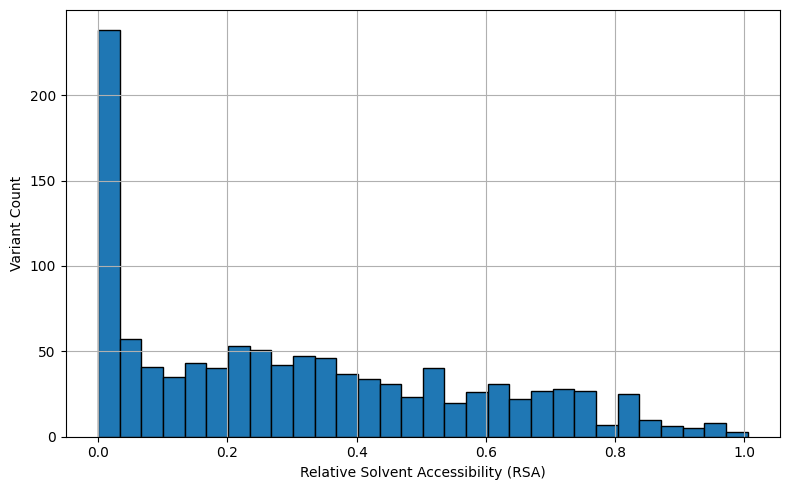

In [ ]:
import pandas as pd
import re

# Load filtered gnomAD variant file
gnomad_path = "filtered_VUS_conflicting_variants.csv"
variants_df = pd.read_csv(gnomad_path)

# Load RSA file
rsa_df = pd.read_csv("rsa_output.csv")

# Step 1: Extract residue position from Protein Consequence (e.g., p.Gly4055Arg → 4055)
def extract_position(consequence):
    match = re.search(r'p\.[A-Z][a-z]{2}(\d+)[A-Z][a-z]{2}', consequence)
    return int(match.group(1)) if match else None

variants_df["Residue_Position"] = variants_df["Protein Consequence"].apply(extract_position)

# Step 2: Merge RSA values by residue number
merged_df = pd.merge(variants_df, rsa_df, left_on="Residue_Position", right_on="ResNum", how="left")

# Step 3: Save the merged DataFrame
output_path = "merged_variants_with_RSA.csv"
merged_df.to_csv(output_path, index=False)

# Optional: show a preview
print(f"Merged data saved to {output_path}")
print(merged_df[["Protein Consequence", "Residue_Position", "RSA"]].head())

import pandas as pd
import matplotlib.pyplot as plt

# Plot RSA distribution
rsa_values = merged_df["RSA"].dropna()
plt.figure(figsize=(8, 5))
plt.hist(rsa_values, bins=30, edgecolor='black')
plt.xlabel("Relative Solvent Accessibility (RSA)")
plt.ylabel("Variant Count")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Load the merged file
merged_df = pd.read_csv("merged_variants_with_RSA.csv")

# Count variants with RSA below 0.25
low_rsa_count = merged_df[merged_df["RSA"] < 0.25].shape[0]
print(f"There are {low_rsa_count} variants with RSA < 0.25")

There are 538 variants with RSA < 0.25


## Finding controversial variants

In [ ]:
merged_df = pd.read_csv("merged_variants_with_RSA.csv")

# Define criteria
filtered_df = merged_df[
    (merged_df["RSA"] < 0.01) &
    (merged_df["Homozygote Count"] == 0) &
    (merged_df["Allele Frequency"] < 1e-6) &
    (merged_df["ClinVar Germline Classification"].isin(["Conflicting interpretations of pathogenicity", "Uncertain significance"]))
]

# Show how many variants pass all the filters
print(f"{len(filtered_df)} variants pass all criteria")
filtered_df.to_csv("controversial.csv", index=False)

print(filtered_df.head())

29 variants pass all criteria
          gnomAD ID  Chromosome  Position         rsIDs Reference Alternate  \
143  6-51638924-C-T           6  51638924   rs962553557         C         T   
174  6-51658965-C-T           6  51658965  rs1305304437         C         T   
281  6-51746788-C-T           6  51746788   rs895942963         C         T   
283  6-51746796-G-C           6  51746796  rs1307732644         G         C   
291  6-51747799-T-G           6  51747799  rs1562221107         T         G   

            Source Filters - exomes Filters - genomes         Transcript  ...  \
143  gnomAD Exomes             PASS               NaN  ENST00000371117.8  ...   
174  gnomAD Exomes             PASS               NaN  ENST00000371117.8  ...   
281  gnomAD Exomes             PASS               NaN  ENST00000371117.8  ...   
283  gnomAD Exomes             PASS               NaN  ENST00000371117.8  ...   
291  gnomAD Exomes             PASS               NaN  ENST00000371117.8  ...   

    Hemi

## Divide into batches for FoldX

In [ ]:
import pandas as pd

# Load the filtered variants
df = pd.read_csv("filtered_VUS_conflicting_variants.csv")

# Number of bins
num_bins = 20

# Create bin labels
bin_labels = [f"Bin_{i+1}" for i in range(num_bins)]

# Assign each row to a bin (preserving original order)
df["Bin"] = pd.cut(
    x=range(len(df)),
    bins=num_bins,
    labels=bin_labels
)

# Print each bin
for label in bin_labels:
    bin_df = df[df["Bin"] == label]
    print(f"\n=== {label} ({len(bin_df)} variants) ===")
    print(bin_df[["Protein Consequence", "Bin"]])


=== Bin_1 (56 variants) ===
   Protein Consequence    Bin
0         p.Thr2082Ile  Bin_1
1         p.Tyr1136Cys  Bin_1
2         p.Ile2364Asn  Bin_1
3         p.Leu1709Phe  Bin_1
4         p.Ser3210Cys  Bin_1
5         p.Met2841Val  Bin_1
6         p.Ser2861Gly  Bin_1
7         p.Asp3139Tyr  Bin_1
8         p.Glu1448Gly  Bin_1
9          p.Arg723Leu  Bin_1
10        p.Val3263Ala  Bin_1
11        p.Gly2782Ala  Bin_1
12          p.Asn53Ser  Bin_1
13        p.Ala3072Val  Bin_1
14        p.Gln1923Leu  Bin_1
15        p.Ser3289Ile  Bin_1
16        p.Ala3742Thr  Bin_1
17        p.Pro3780Ser  Bin_1
18         p.Arg909Gln  Bin_1
19         p.Gly448Arg  Bin_1
20        p.Phe2779Val  Bin_1
21        p.Pro2582Ser  Bin_1
22        p.Gly2285Glu  Bin_1
23        p.Ala1279Thr  Bin_1
24        p.Arg2604Cys  Bin_1
25         p.Val732Phe  Bin_1
26         p.Ala109Thr  Bin_1
27         p.Thr642Ile  Bin_1
28         p.Arg559Gln  Bin_1
29        p.Val3471Ile  Bin_1
30        p.Asn3235Lys  Bin_1
31         

##**Plotting allele frequency with structural features**

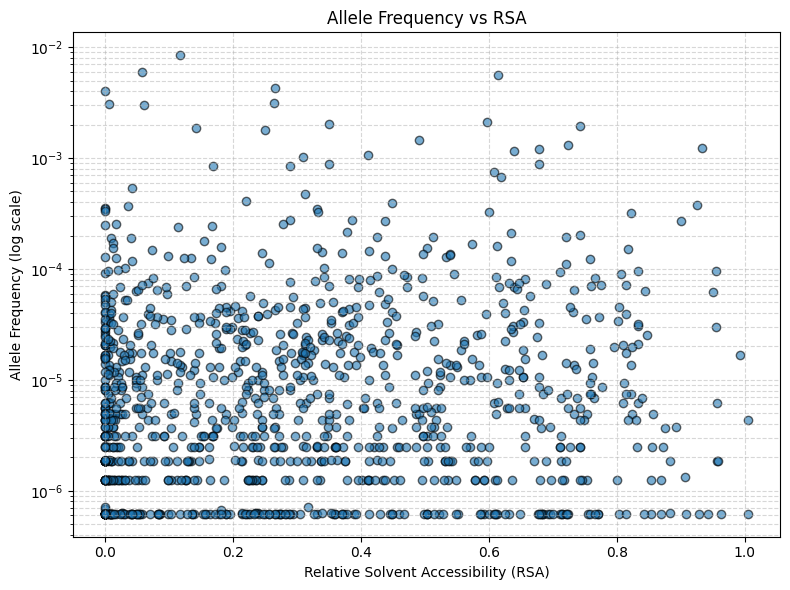

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load merged dataset
merged_df = pd.read_csv("merged_variants_with_RSA.csv")

# Keep only rows with both values present
plot_df = merged_df.dropna(subset=["RSA", "Allele Frequency"])

# Scatter plot with switched axes
plt.figure(figsize=(8, 6))
plt.scatter(plot_df["RSA"], plot_df["Allele Frequency"], alpha=0.6, edgecolor='k')
plt.yscale("log")  # log scale for allele frequency
plt.xlabel("Relative Solvent Accessibility (RSA)")
plt.ylabel("Allele Frequency (log scale)")
plt.title("Allele Frequency vs RSA")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

